# Q1.

In [10]:
import numpy as np

X = np.array([[1,1],
              [3,4]])
print(f'Matrix Rank: {np.linalg.matrix_rank(X)}')
print(f'Determinant: {np.linalg.det(X)}')

Matrix Rank: 2
Determinant: 0.9999999999999998


In [11]:
inv_X = np.linalg.inv(X)
print(f'Inverse Matrix:\n{inv_X}')

Inverse Matrix:
[[ 4. -1.]
 [-3.  1.]]


In [4]:
y = np.array([[0],
              [1]])
w = np.matmul(inv_X, y)
print(w)

[[-1.]
 [ 1.]]


In [5]:
print(inv_X@y)

[[-1.]
 [ 1.]]


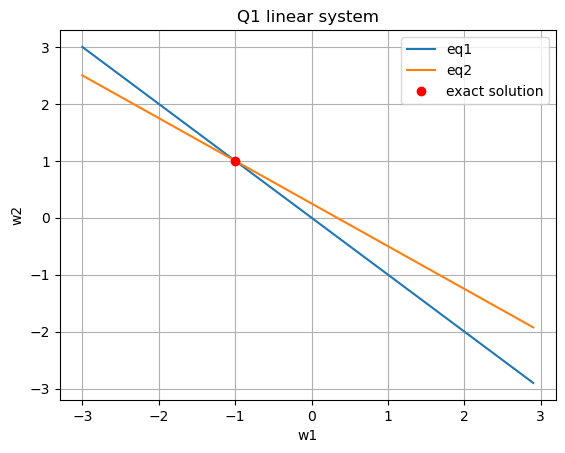

In [6]:
import matplotlib.pyplot as plt

w1 = np.arange(-3,3,0.1)
w2_1 = (0-w1)/1
w2_2 = (1-3*w1)/4

plt.plot(w1,w2_1,label='eq1')
plt.plot(w1,w2_2,label='eq2')
plt.plot(w[0], w[1], 'ro', label='exact solution')

plt.legend()
plt.xlabel('w1')
plt.ylabel('w2')
plt.title('Q1 linear system')
plt.grid()
plt.show()

In [7]:
A = np.array([1,2,3])
B = np.array([[1], 
              [2], 
              [3]])

In [8]:
A.shape

(3,)

In [9]:
B.shape

(3, 1)

# Q2.

*Although you can find two-sided inverse of $ \begin{pmatrix} 1 & 2 \\ 3 & 6 \end{pmatrix} $ using `numpy 2.2.5`, it is actually a numerical error*

In [12]:
X = np.array([[1,2],
              [3,6]])
inv_X = np.linalg.inv(X)
print(inv_X)

[[-1.80143985e+16  6.00479950e+15]
 [ 9.00719925e+15 -3.00239975e+15]]


*We can find that the determinant value is not reasonable, and the rank is actually 1*

In [13]:
print(f'determinant: {np.linalg.det(X)}')
print(f'matrix rank: {np.linalg.matrix_rank(X)}')

determinant: -3.330669073875464e-16
matrix rank: 1


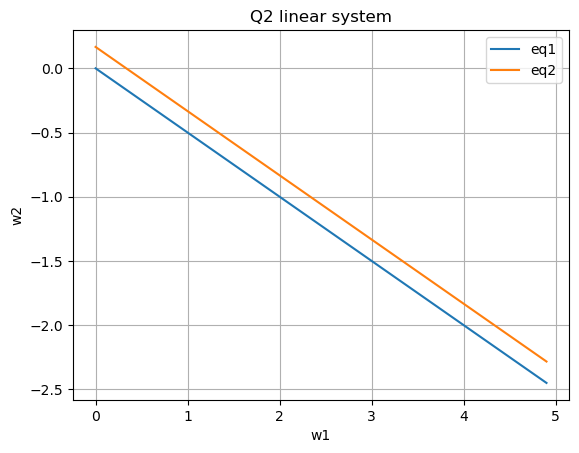

In [14]:
import matplotlib.pyplot as plt

w1 = np.arange(0,5,0.1)
w2_1 = (0-w1)/2
w2_2 = (1-3*w1)/6

plt.plot(w1,w2_1,label='eq1')
plt.plot(w1,w2_2,label='eq2')
plt.legend()
plt.xlabel('w1')
plt.ylabel('w2')
plt.title('Q2 linear system')
plt.grid()
plt.show()

# Q3.

In [15]:
X = np.array([[1,2],
              [2,4],
              [1,-1]])

y = np.array([[0],
              [0.1],
              [1]])

**Approximate w through Least squares: $\arg\min_{w}||Xw-y||^2$**

In [16]:
w = np.linalg.inv(X.T @ X) @ X.T @ y
print(w)

[[ 0.68]
 [-0.32]]


**Let's try to visualize this approximated w**

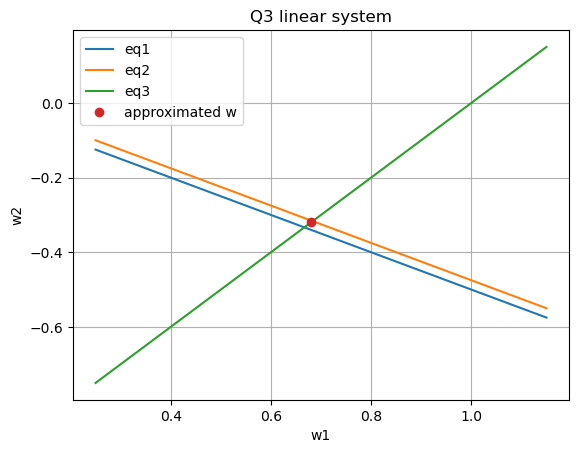

In [17]:
w1 = np.arange(0.25,1.25,0.1)
w2_1 = (0-w1)/2
w2_2 = (0.1-2*w1)/4
w2_3 = (1-w1)/-1

plt.plot(w1,w2_1,label='eq1')
plt.plot(w1,w2_2,label='eq2')
plt.plot(w1,w2_3,label='eq3')
plt.plot(w[0], w[1],'o',label='approximated w')

plt.legend()
plt.xlabel('w1')
plt.ylabel('w2')
plt.title('Q3 linear system')
plt.grid()
plt.show()

# Q4.

**Constrain w through minimum norm: $\arg\min_{w}\frac{1}{2}||w||^2, s.t. Xw=y$**

In [18]:
X = np.array([[1,0,1,0],
              [1,-1,1,-1],
              [1,1,0,0]])
y = np.array([[1],
              [0],
              [1]])
w = X.T@np.linalg.inv(X@X.T)@y
print(w)

[[0.5]
 [0.5]
 [0.5]
 [0.5]]


*Although you can still find the Left-inverse using Python, it is a **numerical error***

Usually, non-square matrices only have left inverse, or right inverse, or neither of these two.

In [19]:
print(np.linalg.inv(X.T @ X) @ X.T @ y)

[[0.5]
 [1. ]
 [0. ]
 [0. ]]


Rank definicient

In [20]:
print(f'matrix rank of XTX: {np.linalg.matrix_rank(X.T @ X)}')
print(f'dimension of XTX: {np.shape(X.T @ X)}')

matrix rank of XTX: 3
dimension of XTX: (4, 4)


# Q5.

*This is expected to be found for singular matrices*

In [ ]:
X = np.array([[1,3],
              [2,6]])
np.linalg.inv(X)

LinAlgError: Singular matrix

# Q6.

In [17]:
X = np.array([[1,2],
              [2,4],
              [1,-1]])
y = np.array([[0],
              [1]])

X = X.T
w = X.T@np.linalg.inv(X@X.T)@y
print(w)

[[ 0.06666667]
 [ 0.13333333]
 [-0.33333333]]


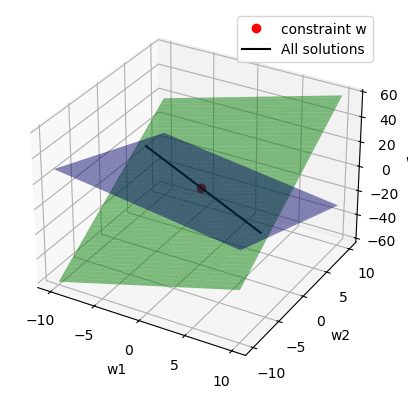

In [18]:
w1 = np.linspace(-10, 10, 100)
w2 = np.linspace(-10, 10, 100)

XX, YY = np.meshgrid(w1, w2)
Z_1 = (0-XX-2*YY)/1
Z_2 = (1-2*XX-4*YY)/-1
    
# Null space via SVD
U, S, Vt = np.linalg.svd(X)
n = Vt[-1]            # null-space direction (last right-singular vector)
n = n / np.linalg.norm(n)
t = np.linspace(-10, 10, 100)
W = w.reshape(3,1) + n.reshape(3,1) * t


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(XX, YY, Z_1, color='b', alpha=0.5)
ax.plot_surface(XX, YY, Z_2, color='g', alpha=0.5)
ax.plot(w[0], w[1], w[2], 'o',label='constraint w', color='r')
ax.plot(W[0,:], W[1,:], W[2,:], c='k', label='All solutions')

# Set labels
ax.set_xlabel('w1')
ax.set_ylabel('w2')
ax.set_zlabel('w3')
ax.legend()

# Show the plot
plt.show()

# Q7.

In [23]:
X = np.array([[2,0,0],[0,0,1]])
print(f'Determinant: {np.linalg.det(X.T@X)}')
print(f'Matrix Rank: {np.linalg.matrix_rank(X.T@X)}')

Determinant: 0.0
Matrix Rank: 2


# Q8.

In [24]:
A = np.array([[1,2,3],[4,5,6]])
print(np.linalg.det(A@A.T))

54.00000000000001


# Check for LEFT/RIGHT inverse

In [25]:
import numpy as np
def checkLR(X):
    '''
    Idea: Left inverse exists means full column rank, Right inverse exists means full row rank
    '''
    X = np.array(X)
    m,n = np.shape(X)
    mat_rank = np.linalg.matrix_rank(X)

    if m != n:  # Non-square
        if mat_rank == m:   # Full row rank
            print('Right inverse exists')
            Rinv = X.T @ np.linalg.inv(X @ X.T)
            print(f'Right inverse: \n{Rinv}')
        if mat_rank == n:   # Full column rank
            print('Left inverse exists')
            Linv = np.linalg.inv(X.T @ X) @ X.T
            print(f'Left inverse: \n{Linv}')
        if mat_rank != n and mat_rank != m:
            print('Neither right or left inverse founded')
    else:   # Square matrix
        if mat_rank == m:    # Full rank
            Twoinv = np.linalg.inv(X)
            print('Two-sided inverse exists')
            print(f'Two-sided inverse: \n{Twoinv}')
        else:
            print('Singular square matrix')

In [26]:
X = np.array([[1, 2, 3], [1, -2, 3]])
checkLR(X)

Right inverse exists
Right inverse: 
[[ 0.05  0.05]
 [ 0.25 -0.25]
 [ 0.15  0.15]]


# Reference code for linear eqs syetems
**Assume canonical system setup: $Xw=y$, apply transpose on both side if ncessary**
## Part I: Analyze the system: solution type
**Idea: Analyze a linear equation system from 2 independent dimensions**:
1. **Consistency** (existence of exact solutions): Roche-Capelli Theorem
2. **Uniqueness** (numbers of solutions): Rank-Nullity Theorem

*For all cases, a canonical solution (the minimum-norm or least-squares solution) can be acquired from the Moore–Penrose pseudoinverse ($X^{+}$): `np.pinv()`* 


| Item                        | Exact solution        | NO exact solution |
| :---                        | :---                  | :--- |
| **Unique solution**         | Unique exact solution | Unique least-squares solution |
| **Infinitely many solution**|Infinitely many exact solutions <br>(minimum-norm returned) <br/> | Infinitely many least-squares solutions <br>(minimum-norm returned) <br/> |

## Part II: Tutorial 4 Take-away: Rule-of-thumb pipeline
**Idea: Choose inverse algorithm from system shape**:
1. If $X$ is square and invertible, use *two-sided* inverse: $X^{-1}$
2. If $X$ is tall and full column-rank, use *left* inverse: $(X^TX)^{-1}X^T$
3. If $X$ is wide and full row-rank, use *right* inverse: $X^T(XX^T)^{-1}$

In [29]:
import numpy as np
from pprint import pprint

def analyze_linear_system(X, y, tol=1e-10):
    """
    Analyze the linear system X w = y.

    Parameters:
        X (np.ndarray): Data matrix of shape (m, d).
        y (np.ndarray): Target vector of shape (m, 1).
        tol (float): Tolerance for rank determination.

    Returns:
        result (dict): {
            'consistent': bool,
            'solution_type': str,
            'rank_X': int,
            'rank_augmented': int,
            'nullity': int,
            'solution': np.ndarray,
            'residual_norm': float
        }
    """

    X = np.atleast_2d(X)
    y = np.atleast_1d(y)

    m, d = X.shape

    # Ranks
    rank_X = np.linalg.matrix_rank(X, tol=tol)
    rank_aug = np.linalg.matrix_rank(
        np.hstack([X, y.reshape(-1, 1)]),
        tol=tol
    )

    # Nullity (Rank–Nullity Theorem)
    nullity = d - rank_X

    # Moore-Penrose pseudoinverse: very robust in all cases
    X_pinv = np.linalg.pinv(X, rcond=tol)
    w_star = X_pinv @ y

    # Residual
    residual_norm = np.linalg.norm( X @ w_star - y)

    # Consistency check (RC theorem)
    consistent = (rank_X == rank_aug)

    # Solution classification
    if consistent:
        if nullity == 0:
            solution_type = "Unique exact solution"
        else:
            solution_type = "Infinitely many exact solutions (minimum-norm returned)"
    else:
        if nullity == 0:
            solution_type = "Unique least-squares solution"
        else:
            solution_type = "Infinitely many least-squares solutions (minimum-norm returned)"
    

    ## Enhance of two-sided/L/R inverse mentioned in Tut4
    inverse_type_tut4 = None
    w_star_tut4 = None
    residual_norm_tut4 = None
    
    if m == d and rank_X == d:     # Two-sided inverse exists
        two_inv = np.linalg.inv(X)
        w_star_tut4 = two_inv @ y
        inverse_type_tut4 = "Two-sided inverse"
    elif m >= d and rank_X == d:   # Full column rank: Left inverse exists
        L_inv = np.linalg.inv(X.T @ X) @ X.T
        w_star_tut4 = L_inv @ y
        inverse_type_tut4 = "Left inverse"
    elif m <= d and rank_X == m:   # Full row rank: Right inverse exists
        R_inv = X.T @ np.linalg.inv(X @ X.T)
        w_star_tut4 = R_inv @ y
        inverse_type_tut4 = "Right inverse"
    else:
        inverse_type_tut4 = "Not in Tut4 inverse cases, pseudoinverse used"
        X_pinv = np.linalg.pinv(X, rcond=tol)
        w_star_tut4 = X_pinv @ y  # Use pseudoinverse as fallback

    
    # Residual in Tut4 method
    residual_norm_tut4 = np.linalg.norm(X @ w_star_tut4 - y)

    result_pinv = {
        "consistent": consistent,
        "solution_type": solution_type,
        "rank_X": rank_X,
        "rank_augmented": rank_aug,
        "nullity": nullity,
        "solution": w_star,
        "residual_norm": residual_norm,
    }

    result_tut4 = {
        "inverse_type_tut4": inverse_type_tut4,
        "solution_tut4": w_star_tut4,
        "residual_norm_tut4": residual_norm_tut4,
    }

    return result_pinv, result_tut4

In [32]:
X = np.array([[1,0,1,0],
              [1,-1,1,-1],
              [1,1,0,0]])
y = np.array([[1],
              [0],
              [1]])

result_pinv, result_tut4 = analyze_linear_system(X, y)
print(f'System analysis with pseudoinverse:')
pprint(result_pinv)
print(f'\nSystem analysis with Tut4 method:')
pprint(result_tut4)

System analysis with pseudoinverse:
{'consistent': True,
 'nullity': 1,
 'rank_X': 3,
 'rank_augmented': 3,
 'residual_norm': 3.1401849173675503e-16,
 'solution': array([[0.5],
       [0.5],
       [0.5],
       [0.5]]),
 'solution_type': 'Infinitely many exact solutions (minimum-norm returned)'}

System analysis with Tut4 method:
{'inverse_type_tut4': 'Right inverse',
 'residual_norm_tut4': 0.0,
 'solution_tut4': array([[0.5],
       [0.5],
       [0.5],
       [0.5]])}
